# 🔗 Live Deployment Link: https://YOUR-APP-NAME.streamlit.app/
*(Replace the link above with your own Streamlit Cloud URL before submitting.)*

# Heart Disease Prediction System
**Course:** AIC354 – Machine Learning Fundamentals | **Assignment 2, Task 2**

**Dataset:** UCI Heart Disease (Cleveland) – https://archive.ics.uci.edu/dataset/45/heart+disease

**Selected 4 input attributes (constraint):**
| Attribute | Meaning | Type |
|---|---|---|
| `age` | Age in years | Numeric |
| `sex` | Sex (Female / Male) | Categorical → Label Encoded |
| `cp` | Chest pain type | Categorical → Label Encoded |
| `thalach` | Maximum heart rate achieved | Numeric |

**Target:** `target` → 0 = No heart disease, 1 = Heart disease present

## Phase 1 – Data Collection

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

In [17]:
# Original UCI column names (the raw file has no header row)
columns = ["age","sex","cp","trestbps","chol","fbs","restecg",
           "thalach","exang","oldpeak","slope","ca","thal","target"]

LOCAL_RAW = "processed.cleveland.data"
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# Use the local file if you downloaded it from UCI, otherwise download directly
source = LOCAL_RAW if os.path.exists(LOCAL_RAW) else URL
df = pd.read_csv(source, names=columns, na_values="?")
print("Loaded from:", source)
print("Shape:", df.shape)
df.head()

Loaded from: https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Phase 2 – Data Understanding

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [19]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [20]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nOriginal target values (0 = healthy, 1-4 = disease severity):")
print(df["target"].value_counts().sort_index())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Original target values (0 = healthy, 1-4 = disease severity):
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


## Phase 3 – Data Preprocessing

**Steps**
1. Keep only the 4 chosen input attributes + the target.
2. Convert the target to binary (0 = no disease, 1 = disease).
3. Handle missing values.
4. Convert coded categorical values into readable text, then apply **Label Encoding**.

In [21]:
selected = ["age", "sex", "cp", "thalach"]
data = df[selected + ["target"]].copy()

# Binary target: any value > 0 means heart disease present
data["target"] = (data["target"] > 0).astype(int)

# Missing values (these 4 columns have none in the Cleveland data, but we check anyway)
print("Missing values in selected columns:\n", data.isnull().sum())
data = data.dropna().reset_index(drop=True)
print("\nShape after cleaning:", data.shape)

Missing values in selected columns:
 age        0
sex        0
cp         0
thalach    0
target     0
dtype: int64

Shape after cleaning: (303, 5)


In [22]:
# Turn numeric codes into readable categories (like 'male'/'female' in Titanic)
data["sex"] = data["sex"].map({0: "Female", 1: "Male"})
data["cp"]  = data["cp"].map({1: "Typical Angina",
                              2: "Atypical Angina",
                              3: "Non-anginal Pain",
                              4: "Asymptomatic"})
data.head()

,age,sex,cp,thalach,target
0,63.0,Male,Typical Angina,150.0,0
1,67.0,Male,Asymptomatic,108.0,1
2,67.0,Male,Asymptomatic,129.0,1
3,37.0,Male,Non-anginal Pain,187.0,0
4,41.0,Female,Atypical Angina,172.0,0


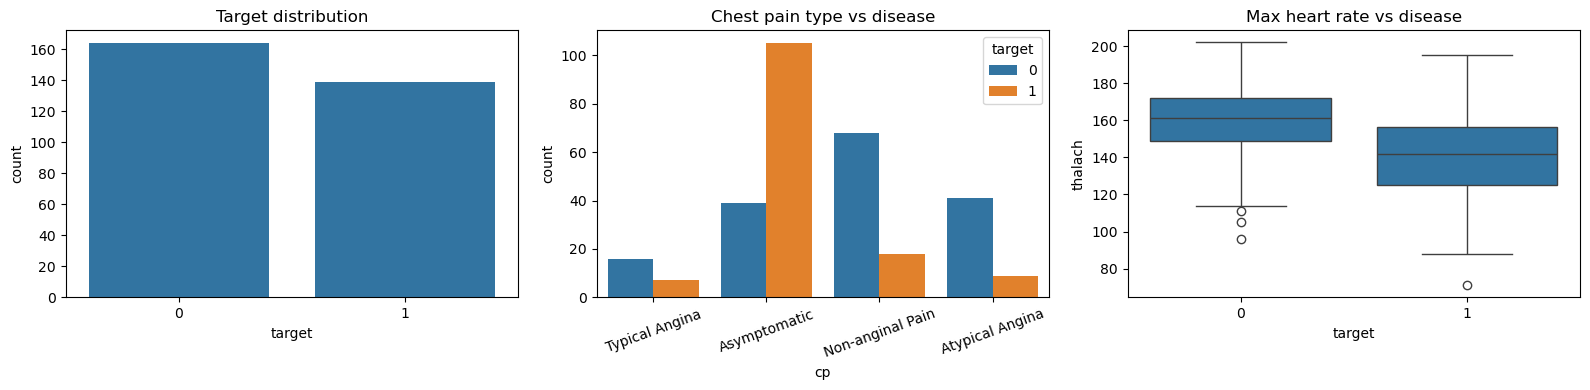

In [23]:
# Exploratory plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="target", data=data, ax=ax[0]); ax[0].set_title("Target distribution")
sns.countplot(x="cp", hue="target", data=data, ax=ax[1]); ax[1].set_title("Chest pain type vs disease")
ax[1].tick_params(axis="x", rotation=20)
sns.boxplot(x="target", y="thalach", data=data, ax=ax[2]); ax[2].set_title("Max heart rate vs disease")
plt.tight_layout(); plt.show()

### Label Encoding

In [24]:
le_sex = LabelEncoder()
le_cp  = LabelEncoder()

data["sex"] = le_sex.fit_transform(data["sex"])
data["cp"]  = le_cp.fit_transform(data["cp"])

print("sex mapping:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("cp  mapping:", dict(zip(le_cp.classes_,  le_cp.transform(le_cp.classes_))))
data.head()

sex mapping: {'Female': np.int64(0), 'Male': np.int64(1)}
cp  mapping: {'Asymptomatic': np.int64(0), 'Atypical Angina': np.int64(1), 'Non-anginal Pain': np.int64(2), 'Typical Angina': np.int64(3)}


,age,sex,cp,thalach,target
0,63.0,1,3,150.0,0
1,67.0,1,0,108.0,1
2,67.0,1,0,129.0,1
3,37.0,1,2,187.0,0
4,41.0,0,1,172.0,0


## Phase 4 – Model Building, Evaluation & Deployment (ML Cycle)

### 4.1 Train / Test split

In [25]:
X = data[selected]
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (242, 4)  Test: (61, 4)


### 4.2 Train and compare models

In [26]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
}

results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, m.predict(X_test))
    cv_acc = cross_val_score(m, X, y, cv=5).mean()
    results[name] = (test_acc, cv_acc)
    print(f"{name:22s} Test acc: {test_acc:.3f} | 5-fold CV acc: {cv_acc:.3f}")

Logistic Regression    Test acc: 0.738 | 5-fold CV acc: 0.762
Decision Tree          Test acc: 0.820 | 5-fold CV acc: 0.706
Random Forest          Test acc: 0.770 | 5-fold CV acc: 0.733


### 4.3 Evaluate the best model

Best model: Logistic Regression

Accuracy: 0.738

               precision    recall  f1-score   support

  No Disease       0.73      0.82      0.77        33
     Disease       0.75      0.64      0.69        28

    accuracy                           0.74        61
   macro avg       0.74      0.73      0.73        61
weighted avg       0.74      0.74      0.74        61



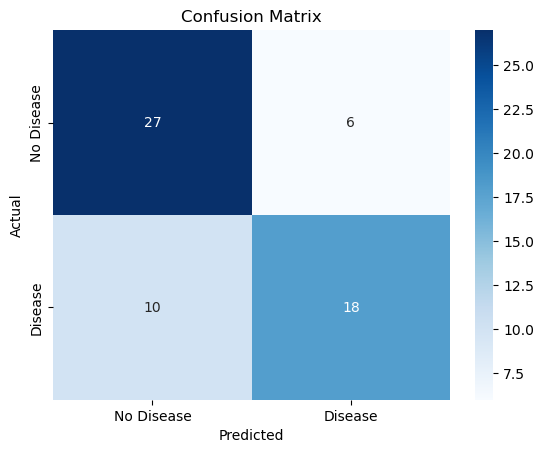

In [12]:
best_name = max(results, key=lambda k: results[k][1])   # pick by cross-validation score
model = models[best_name]
print("Best model:", best_name)

y_pred = model.predict(X_test)
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\n", classification_report(y_test, y_pred, target_names=["No Disease", "Disease"]))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix"); plt.show()

### 4.4 Save model and encoders, then test a prediction

In [13]:
os.makedirs("model", exist_ok=True)
joblib.dump(model,  "model/heart_model.pkl")
joblib.dump(le_sex, "model/le_sex.pkl")
joblib.dump(le_cp,  "model/le_cp.pkl")

# Save the cleaned dataset for submission
df.to_csv("heart_disease.csv", index=False)
print("Saved: model/heart_model.pkl, model/le_sex.pkl, model/le_cp.pkl, heart_disease.csv")

Saved: model/heart_model.pkl, model/le_sex.pkl, model/le_cp.pkl, heart_disease.csv


In [14]:
# Sanity check: load the saved model and predict for a new patient
m  = joblib.load("model/heart_model.pkl")
ls = joblib.load("model/le_sex.pkl")
lc = joblib.load("model/le_cp.pkl")

sample = pd.DataFrame([{
    "age": 58,
    "sex": ls.transform(["Male"])[0],
    "cp":  lc.transform(["Asymptomatic"])[0],
    "thalach": 120
}])[selected]

pred = m.predict(sample)[0]
prob = m.predict_proba(sample)[0][1]
print("Prediction:", "Heart disease likely" if pred == 1 else "No heart disease")
print(f"Probability of disease: {prob:.2%}")

Prediction: Heart disease likely
Probability of disease: 89.45%


## Deployment
The trained model is deployed with **Streamlit Community Cloud** (connected to my GitHub repo).
The app code is in `app.py`; it loads `model/heart_model.pkl` and the two encoders.

**Live link:** see the top of this notebook.